# 02_LazyPredict — Comparación exploratoria de modelos

**EV3 · Spotify · CRISP-DM: modelación inicial**

Este notebook continúa `01_EDA`. Compara siete clasificadores con la representación completa del género antes de estudiar PCA. El objetivo es identificar candidatos, no declarar un ganador definitivo.

Se utiliza exclusivamente `data/raw/train/raw_train.csv`. El test final no se lee. Se crea una validación interna agrupada por `song_key`. El P80=52 definido en el EDA se mantiene como definición fija del objetivo: no se recalcula por partición.

Ejecutar después de 01_EDA. Instalar una vez desde la raíz: `python -m pip install -r requirements_lazypredict.txt`.

## 1. Entorno y configuración
Las funciones están en `src/benchmark.py`. Se fija la semilla 42 y se usan todas las canciones del train original, sin muestreo para acelerar ni ajuste de hiperparámetros. El tiempo dependerá del equipo.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/benchmark.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Copia src/benchmark.py en el proyecto junto a src/pipeline.py.")
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.benchmark import preparar, ejecutar
TABLAS = ROOT / "output/tablas"
GRAFICOS = ROOT / "output/graficos"
TABLAS.mkdir(parents=True, exist_ok=True)
GRAFICOS.mkdir(parents=True, exist_ok=True)
SEED = 42

## 2. Validación interna y preprocesamiento sin fuga
Se separa aproximadamente 80/20 del train original por grupos, sin versiones compartidas. La proporción de filas puede diferir de 80/20.

El vocabulario de géneros y el one-hot de `key`/`time_signature` se ajustan solo con el entrenamiento interno. Las etiquetas desconocidas de validación no crean columnas nuevas. Los logs y variables simples del texto replican el EDA.

LazyPredict añade imputación y escalado numérico en su propio pipeline, aprendidos solo con entrenamiento interno. Los datos entregados son numéricos e incluyen audio, texto simple y géneros completos; no se usa PCA todavía. El benchmark no llama a la CV automática de LazyPredict, que no se ha configurado para nuestros grupos.

La matriz puede tener más columnas que las 133 exportadas en el EDA: aquí `key` y `time_signature` ya se expandieron mediante one-hot (148 columnas en la ejecución incluida).

In [2]:
X_fit, X_val, y_fit, y_val, metadata, ids = preparar(ROOT, seed=SEED)
resumen = pd.DataFrame({"particion":["entrenamiento interno", "validación interna"],
                        "filas":[len(y_fit),len(y_val)],
                        "proporcion_hit":[y_fit.mean(),y_val.mean()]})
display(resumen)
print("Variables:", X_fit.shape[1])
print("Géneros aprendidos:", metadata["n_generos"])
print("Filas de validación con género desconocido:", metadata["filas_validacion_genero_desconocido"])
print("Sin grupos compartidos. Test final no leído.")
ids.to_csv(TABLAS / "10_particion_benchmark.csv", index=False)
resumen.to_csv(TABLAS / "11_resumen_benchmark.csv", index=False)
(TABLAS / "12_configuracion_benchmark.json").write_text(json.dumps(metadata,indent=2),encoding="utf-8");

,particion,filas,proporcion_hit
0,entrenamiento interno,57423,0.209672
1,validación interna,14283,0.211930


Variables: 148
Géneros aprendidos: 114
Filas de validación con género desconocido: 0
Sin grupos compartidos. Test final no leído.


## 3. Modelos comparados con LazyPredict

| Modelo | Papel en la comparación |
|---|---|
| DummyClassifier | Referencia sin aprendizaje de las características |
| LogisticRegression | Referencia lineal |
| DecisionTreeClassifier | Árbol individual para contrastar con ensambles |
| GaussianNB | Referencia probabilística sencilla |
| RandomForestClassifier | Ensamble con bootstrap y aleatoriedad en variables |
| ExtraTreesClassifier | Ensamble de árboles con mayor aleatoriedad en los cortes |
| HistGradientBoostingClassifier | Boosting basado en histogramas |

Se usan configuraciones iniciales de las clases; no se supone que sean óptimas. No se incluyen todos los algoritmos disponibles porque este benchmark acotado cubre distintas familias y mantiene un costo razonable. Los errores se registran y las advertencias no se ocultan.

In [3]:
tabla_lazy, resultados, errores, tiempo_total = ejecutar(X_fit, X_val, y_fit, y_val, seed=SEED)
display(tabla_lazy.round(4))
print(f"Tiempo total del benchmark y métricas complementarias: {tiempo_total:.1f} s")
print("Modelos completados:", len(resultados), "/", len(metadata["modelos"]))
print("Errores:", errores if errores else "Ninguno")
tabla_lazy.to_csv(TABLAS / "13_lazypredict_original.csv")
(TABLAS / "14_errores_benchmark.json").write_text(json.dumps(errores,indent=2),encoding="utf-8");

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
ExtraTreesClassifier,0.8449,0.7230,0.8754,0.8365,0.8345,0.8449,19.1533
GaussianNB,0.5911,0.7191,0.7553,0.6225,0.8347,0.5911,0.3872
RandomForestClassifier,0.8433,0.6943,0.8687,0.8283,0.8310,0.8433,17.9845
DecisionTreeClassifier,0.7837,0.6917,0.6953,0.7868,0.7905,0.7837,4.6196
HistGradientBoostingClassifier,0.8331,0.6610,0.8645,0.8113,0.8185,0.8331,3.4308
LogisticRegression,0.8201,0.6389,0.8426,0.7957,0.8001,0.8201,0.6146
DummyClassifier,0.7881,0.5000,0.5000,0.6947,0.6211,0.7881,0.2740


Tiempo total del benchmark y métricas complementarias: 52.1 s
Modelos completados: 7 / 7
Errores: Ninguno


## 4. Métricas relacionadas con la promoción
AUC y average precision se calculan con probabilidades de hit. Average precision resume la curva precisión-recall; su referencia es la proporción de hits de validación.

Recall, precisión y F1 corresponden a la decisión predeterminada de cada modelo, sin ajustar umbrales. Lift@10% compara la tasa de hits del 10% mejor puntuado con la tasa global de validación. En una puntuación constante se informa lift esperado=1, porque no existe ordenación informativa. En otros empates se mantiene un orden estable.

La brecha AUC train-validación es una señal de sobreajuste, no una estimación completa de generalización. `tiempo_lazy_s` incluye ajuste y evaluación estándar de LazyPredict; no es latencia de predicción ni incluye la preparación externa.

La tabla original puede usar promedios de F1 distintos; aquí `f1_hit` siempre corresponde a la clase positiva.

,auc_validacion,average_precision,precision,recall,f1_hit,balanced_accuracy,lift_10,auc_train,gap_auc,tiempo_lazy_s
modelo,,,,,,,,,,
ExtraTreesClassifier,0.8754,0.6728,0.6775,0.5114,0.5828,0.7230,3.5827,0.9999,0.1245,19.1533
RandomForestClassifier,0.8687,0.6669,0.7134,0.4357,0.5410,0.6943,3.5100,0.9995,0.1308,17.9845
HistGradientBoostingClassifier,0.8645,0.6506,0.7073,0.3624,0.4792,0.6610,3.4143,0.8901,0.0256,3.4308
LogisticRegression,0.8426,0.5916,0.6521,0.3244,0.4333,0.6389,3.1138,0.8436,0.0010,0.6146
GaussianNB,0.7553,0.3614,0.3347,0.9412,0.4938,0.7191,1.9713,0.7523,-0.0030,0.3872
DecisionTreeClassifier,0.6953,0.3633,0.4904,0.5322,0.5105,0.6917,2.3279,0.9999,0.3046,4.6196
DummyClassifier,0.5000,0.2119,0.0000,0.0000,0.0000,0.5000,1.0000,0.5000,0.0000,0.2740


Referencia average precision: 0.2119


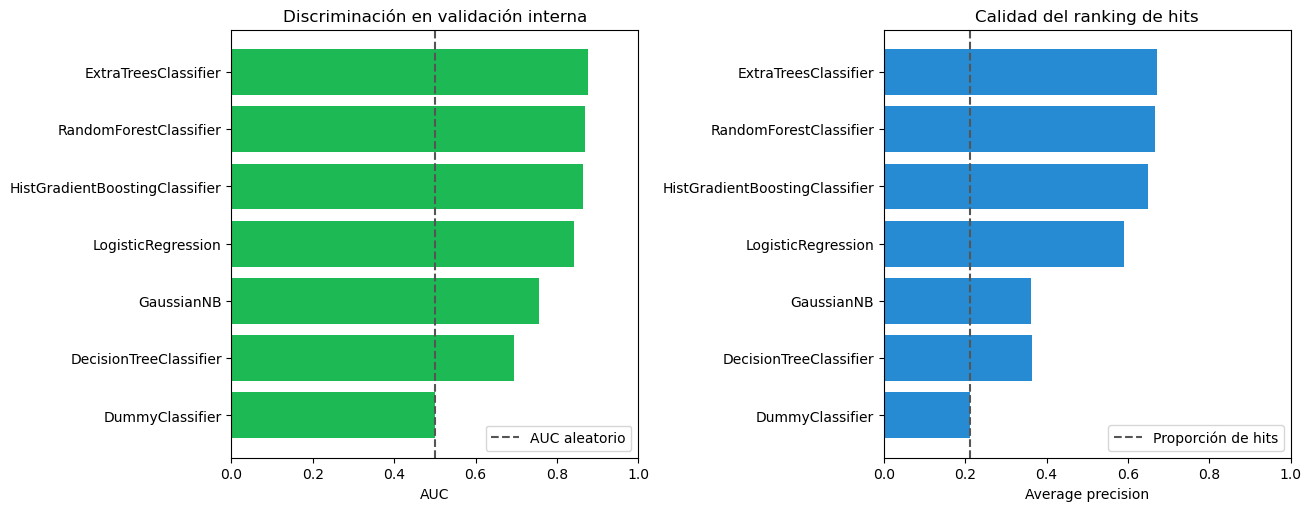

In [4]:
display(resultados.round(4))
resultados.to_csv(TABLAS / "15_benchmark_metricas.csv")
print(f"Referencia average precision: {y_val.mean():.4f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
orden = resultados.sort_values("auc_validacion")
axes[0].barh(orden.index, orden.auc_validacion, color="#1DB954")
axes[0].axvline(.5, color="#555555", linestyle="--", label="AUC aleatorio")
axes[0].set(xlim=(0,1),xlabel="AUC",title="Discriminación en validación interna")
axes[0].legend()
axes[1].barh(orden.index, orden.average_precision, color="#268BD2")
axes[1].axvline(y_val.mean(),color="#555555",linestyle="--",label="Proporción de hits")
axes[1].set(xlim=(0,1),xlabel="Average precision",title="Calidad del ranking de hits")
axes[1].legend()
fig.savefig(GRAFICOS / "08_benchmark_lazypredict.png",dpi=150,bbox_inches="tight")
plt.show()
plt.close(fig)

## 5. Hallazgos calculados y candidatos
La siguiente celda se actualiza al ejecutar. Un buen resultado en una sola partición no prueba estabilidad ni equidad. No se aplican todavía umbrales por género ni se consultan resultados del test final.

In [5]:
primero = resultados.iloc[0]
nombre = resultados.index[0]
texto = f"""**Mejor AUC en esta partición:** {nombre}, con AUC **{primero.auc_validacion:.3f}**, average precision **{primero.average_precision:.3f}** y lift@10% **{primero.lift_10:.2f}**.

Su recall con la decisión inicial es **{primero.recall:.1%}**, precisión **{primero.precision:.1%}** y brecha AUC train-validación **{primero.gap_auc:.3f}**.

Se completaron **{len(resultados)} de {len(metadata['modelos'])}** modelos. Estas cifras son exploratorias y no se usan como evaluación final del proyecto.
"""
display(Markdown(texto))
(TABLAS / "16_hallazgos_benchmark.md").write_text(texto,encoding="utf-8");
ensambles = [n for n in ["RandomForestClassifier", "ExtraTreesClassifier", "HistGradientBoostingClassifier"] if n in resultados.index]
display(resultados.loc[ensambles, ["auc_validacion","recall","precision","gap_auc","tiempo_lazy_s"]].round(4))

**Mejor AUC en esta partición:** ExtraTreesClassifier, con AUC **0.875**, average precision **0.673** y lift@10% **3.58**.

Su recall con la decisión inicial es **51.1%**, precisión **67.7%** y brecha AUC train-validación **0.125**.

Se completaron **7 de 7** modelos. Estas cifras son exploratorias y no se usan como evaluación final del proyecto.


,auc_validacion,recall,precision,gap_auc,tiempo_lazy_s
modelo,,,,,
RandomForestClassifier,0.8687,0.4357,0.7134,0.1308,17.9845
ExtraTreesClassifier,0.8754,0.5114,0.6775,0.1245,19.1533
HistGradientBoostingClassifier,0.8645,0.3624,0.7073,0.0256,3.4308


## 6. Conclusiones y próximos experimentos

- Mantener una referencia simple y contrastar bagging/árboles aleatorizados con boosting. El árbol individual ayuda a mostrar el aporte de combinar estimadores.
- Priorizar los candidatos por AUC y average precision, sin ignorar lift, precisión, recall, sobreajuste y costo. No optimizar buscando cambios favorables en el test.
- Comparar género completo, sin género y PCA con los candidatos seleccionados. El benchmark actual no demuestra el aporte causal del género ni una reducción de sesgo.
- Confirmar el desempeño mediante validación cruzada agrupada y reportar promedio y dispersión. Este notebook usa una sola partición y no cumple por sí solo toda la evaluación de generalización.
- Optimizar hiperparámetros y después estudiar la política de decisión. Los resultados con configuraciones iniciales no son un límite del rendimiento de cada algoritmo.
- Evaluar resultados por género y número de géneros en la etapa correspondiente. No declarar equidad solo porque AUC sea alto.

El test histórico de EV2 sigue reservado y conserva la limitación de haber sido observado previamente. Este notebook no entrena ni guarda el modelo final.

### Interpretación de la ejecución incluida

- **ExtraTrees:** AUC 0,875 y lift@10% 3,58; lidera el ranking, pero la brecha train-validación de 0,125 indica que hay que controlar su complejidad.
- **Random Forest:** AUC 0,869 y brecha 0,131; también requiere regularización y validación agrupada.
- **HistGradientBoosting:** AUC 0,864, lift 3,41 y brecha 0,026; es un candidato por su equilibrio, aunque el recall inicial es 0,362 y necesita estudiar la decisión y/o ponderación de clases.
- **Regresión logística:** AUC 0,843 y brecha 0,001; aporta una referencia simple competitiva.
- **GaussianNB:** recall 0,941, pero precisión 0,335 y lift 1,97. Un recall alto por sí solo no implica una buena priorización promocional. La brecha gap_auc es −0,003 (AUC validación ligeramente mayor que AUC train), lo que no indica mejor generalización sino un artefacto esperado de Naive Bayes: su estimación de probabilidad en entrenamiento está sesgada por la suposición de independencia, mientras que en validación los errores de calibración se compensan parcialmente.
- **Árbol individual:** AUC 0,695 y brecha 0,305; los ensambles lo superan en esta partición. La brecha es la mayor del grupo y se explica porque un árbol sin límite de profundidad memoriza el conjunto de entrenamiento (AUC_train = 0,9999), pero no generaliza: cada hoja termina ajustando ruido en lugar de señal.

Se conservan como candidatos Regresión Logística, Random Forest, HistGradientBoosting y ExtraTrees. La selección definitiva dependerá de CV agrupada, optimización y la comparación de representaciones del género. Estos valores corresponden a la ejecución incluida; al volver a ejecutar, contrastarlos con las tablas actualizadas.
